In [1]:
import xarray as xr
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from pathlib import Path
import sys, os

sys.path.append("/home/548/cd3022/repos/nowcast-evaluation/src")
import metric_aggregation as ma

In [3]:
DIT_PATH = Path("/scratch/er8/cd3022/nowcast-evaluation/error-metric-data/per-forecast/CPDiT")
OF_PATH = Path("/scratch/er8/cd3022/nowcast-evaluation/error-metric-data/per-forecast/GSO_OF")

In [7]:
scores

{'DiT': <xarray.Dataset> Size: 1kB
 Dimensions:    (lead_time: 18)
 Coordinates:
   * lead_time  (lead_time) float64 144B 10.0 20.0 30.0 ... 160.0 170.0 180.0
 Data variables:
     n          (lead_time) int64 144B 1703 1703 1703 1703 ... 1268 1206 975 1150
     rmse       (lead_time) float64 144B 48.62 56.42 62.17 ... 145.1 150.7 156.6
     mae        (lead_time) float64 144B 24.46 29.21 33.01 ... 90.02 94.14 98.89
     ssim       (lead_time) float64 144B 0.7626 0.7331 0.7169 ... 0.5391 0.5289
     fss_small  (lead_time) float64 144B 0.9907 0.9864 0.9835 ... 0.9664 0.9623
     fss_large  (lead_time) float64 144B 0.9989 0.9985 0.9981 ... 0.9915 0.9896,
 'GSO-OF': <xarray.Dataset> Size: 1kB
 Dimensions:    (lead_time: 18)
 Coordinates:
   * lead_time  (lead_time) float64 144B 10.0 20.0 30.0 ... 160.0 170.0 180.0
 Data variables:
     n          (lead_time) int64 144B 1703 1703 1703 1703 ... 1268 1206 975 1150
     rmse       (lead_time) float64 144B 48.36 57.33 63.07 ... 121.9 125.3 130

In [ ]:
# 1. Load per-forecast metrics (dims: time = issue time, lead_time)
metrics = {"DiT": ma.load_metrics(DIT_PATH), "GSO-OF": ma.load_metrics(OF_PATH)}
# 2. Score both models on exactly the same forecasts
metrics = ma.common_sample(metrics)
# 3. Pooled FSS per lead time: 1 - Σdiff / (Σfcst + Σobs)
scores = {m: ma.aggregate(ds) for m, ds in metrics.items()}

In [ ]:
# 4. Uncertainty: bootstrap whole days (forecasts within a day are correlated).
#    Both models use the same resampled days, so their difference is paired.
def daily_fss_sums(ds, window):
    """Per-day sums of the FSS components, shape (component, day, lead_time)."""
    ds = ds.where(ds["valid"] == 1)
    comps = [ds[f"fss_{window}_{c}"].resample(time="1D").sum().fillna(0)
             for c in ("fcst", "obs", "diff")]
    return np.stack([c.transpose("time", "lead_time").values for c in comps])

def bootstrap_fss(metrics, window, n_boot=2000, seed=0):
    sums = {m: daily_fss_sums(ds, window) for m, ds in metrics.items()}
    n_days = next(iter(sums.values())).shape[1]
    idx = np.random.default_rng(seed).integers(0, n_days, size=(n_boot, n_days))
    return {m: 1 - d[idx].sum(1) / (f[idx].sum(1) + o[idx].sum(1))
            for m, (f, o, d) in sums.items()}

/g/data/xp65/public/apps/med_conda/envs/analysis3-25.11/lib/python3.11/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'kerchunk' loading failed:
No module named 'zarr.core.array_spec'; 'zarr.core' is not a package
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


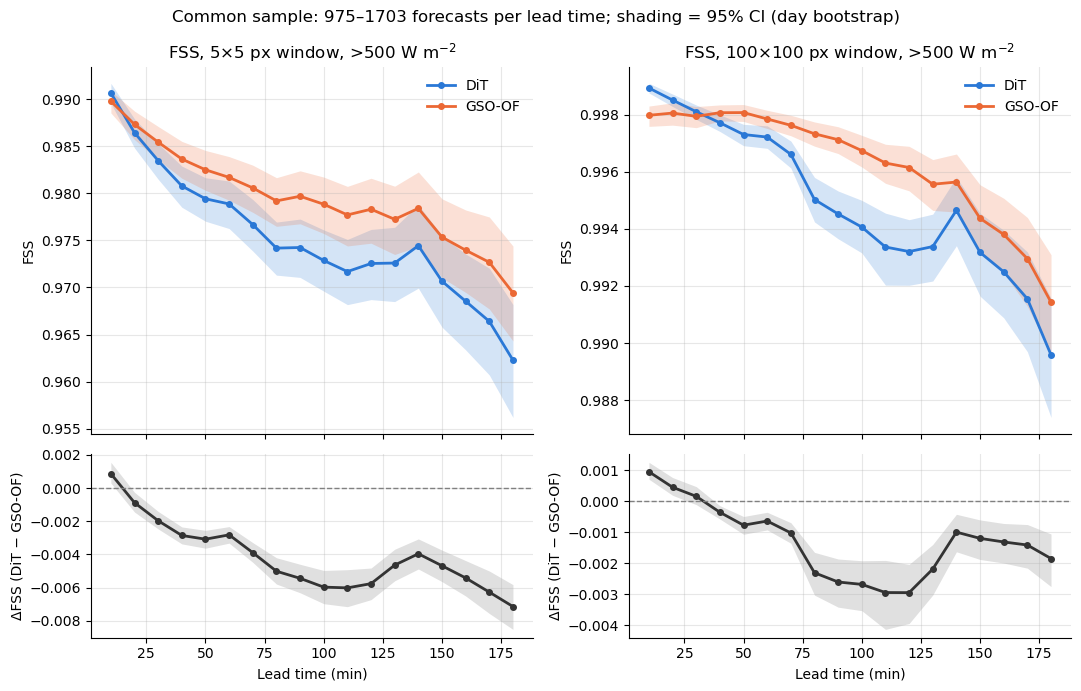

In [4]:
lead = scores["DiT"]["lead_time"].values
colors = {"DiT": "#2a78d6", "GSO-OF": "#eb6834"}
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True, height_ratios=[2, 1])
for col, (window, label) in enumerate([("small", "5×5 px"), ("large", "100×100 px")]):
    boot = bootstrap_fss(metrics, window)
    ax = axes[0, col]
    for m in metrics:
        lo, hi = np.percentile(boot[m], [2.5, 97.5], axis=0)
        ax.fill_between(lead, lo, hi, color=colors[m], alpha=0.2, linewidth=0)
        ax.plot(lead, scores[m][f"fss_{window}"], color=colors[m], lw=2, marker="o", ms=4, label=m)
    ax.set(title=f"FSS, {label} window, >500 W m$^{{-2}}$", ylabel="FSS")
    ax.legend(frameon=False)
    # Paired difference with 95% CI: above zero => DiT more skilful
    ax = axes[1, col]
    lo, hi = np.percentile(boot["DiT"] - boot["GSO-OF"], [2.5, 97.5], axis=0)
    ax.fill_between(lead, lo, hi, color="0.6", alpha=0.3, linewidth=0)
    ax.plot(lead, scores["DiT"][f"fss_{window}"] - scores["GSO-OF"][f"fss_{window}"],
            color="0.2", lw=2, marker="o", ms=4)
    ax.axhline(0, color="0.5", lw=1, ls="--")
    ax.set(ylabel="ΔFSS (DiT − GSO-OF)", xlabel="Lead time (min)")
for ax in axes.flat:
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
n = scores["DiT"]["n"].values
fig.suptitle(f"Common sample: {n.min()}–{n.max()} forecasts per lead time; shading = 95% CI (day bootstrap)")
fig.tight_layout()

In [5]:


dit_files = sorted([f for f in DIT_PATH.glob("*.nc")])
of_files = sorted([f for f in OF_PATH.glob("*.nc")])

In [6]:
dit_metrics = xr.open_mfdataset(dit_files, combine="nested", concat_dim="date")
of_metrics = xr.open_mfdataset(of_files, combine="nested", concat_dim="date")

/jobfs/181094708.gadi-pbs/ipykernel_2087683/3023529963.py:1: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'time' ('time',) The recommendation is to set join explicitly for this case.
  dit_metrics = xr.open_mfdataset(dit_files, combine="nested", concat_dim="date")
/jobfs/181094708.gadi-pbs/ipykernel_2087683/3023529963.py:2: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'time' ('time',) The recommendation is to set join explicitly for this case.
  of_metrics = xr.open_mfdataset(of_files, combine="nested", concat_

In [9]:
# Code for older metric dataset

# fig, ax = plt.subplots(ncols=5, figsize=(15,3))
# for i, met in enumerate(dit_metrics.data_vars):
#     ax[i].plot(dit_metrics[met].mean(dim="date"), label="DiT")
#     ax[i].plot(of_metrics[met].mean(dim="date"), label="OF")
#     ax[i].set_title(met)
#     ax[i].legend()